# Is the disease probability redundant for a linear QC head?

The disease probability `effusion_prob` is nearly a **linear combination** of the delta / attribute / embedding features already fed to the C2 model.

We measure this by regressing `prob` on each config's feature set and reporting the R².
A high R² means a **linear** model (LR) gains ~nothing from also being given `prob` — which is why the "no prob" LR results were basically identical.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

FOLD_CSV = '/zhome/d0/a/221493/thesis/results/C2_custom_corrected/effusion/cv_results_correct_cf/cf_1/fold_0_predictions.csv'
DISEASE  = 'effusion'
df = pd.read_csv(FOLD_CSV)
print(f'{len(df):,} samples,  {df.shape[1]} columns')

9,031 samples,  3491 columns


In [7]:
# --- two tiny helpers -----------------------------------------------------

def cols_of(df, disease):
    """Return the four feature-group column lists (delta / attr / emb / prob)."""
    meta = {f'{disease}_prob', f'{disease}_pred', f'{disease}_true',
            'correct', 'path', 'patient_id', 'cf_prob', 'cf_paths', 'delta_prob'}
    delta = [c for c in df.columns if c.startswith('delta_')]
    emb   = [c for c in df.columns if c.startswith('emb_')]
    attr  = [c for c in df.columns if c not in meta
             and not c.startswith(('delta_', 'emb_', 'cf_attr_', 'cf_emb_',
                                    'LR_', 'RF_', 'MLP_'))]
    return delta, attr, emb

def prob_r2(df, feat_cols, disease):
    """R² of a linear fit predicting disease_prob from feat_cols."""
    X = StandardScaler().fit_transform(df[feat_cols].values.astype(float))
    y = df[f'{disease}_prob'].values
    return r2_score(y, LinearRegression().fit(X, y).predict(X))

In [8]:
# Print the name of each type of columns
for name, cols in zip(['delta', 'attr', 'emb'], cols_of(df, DISEASE)):
    print(f'{name:5} {len(cols):3} columns: {cols[:5]}{"..." if len(cols) > 5 else ""}')

delta 463 columns: ['delta_margin', 'delta_age_pred', 'delta_sex_male', 'delta_sex_female', 'delta_race_white']...
attr  465 columns: ['effusion_prob', 'effusion_true', 'effusion_pred', 'margin', 'age_pred']...
emb   1024 columns: ['emb_0', 'emb_1', 'emb_2', 'emb_3', 'emb_4']...


In [9]:
delta, attr, emb = cols_of(df, DISEASE)

configs = {
    'delta (M2)':          delta,
    'attr':                attr,
    'delta+attr (M3)':     delta + attr,
    'delta+emb (M4)':      delta + emb,
    'delta+attr+emb (M5)': delta + attr + emb,
}

r2 = {name: prob_r2(df, cols, DISEASE) for name, cols in configs.items()}
for name, v in r2.items():
    print(f'{name:24s}  R²(prob) = {v:.3f}')

KeyError: 'cardiomegaly_prob'

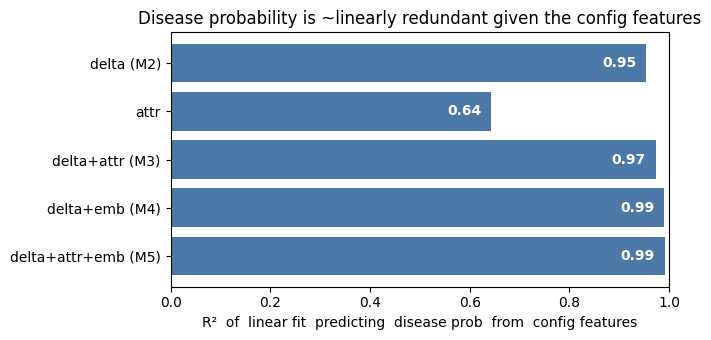

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
names = list(r2)
vals  = [r2[n] for n in names]
ax.barh(names, vals, color='#4C78A8')
for y, v in enumerate(vals):
    ax.text(v - 0.02, y, f'{v:.2f}', va='center', ha='right', color='white', fontweight='bold')
ax.set_xlim(0, 1)
ax.set_xlabel('R²  of  linear fit  predicting  disease prob  from  config features')
ax.set_title('Disease probability is ~linearly redundant given the config features')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('images/prob_redundancy.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway:** with R² ≈ 0.95–0.99, the disease probability is almost a linear combination of the features already present. A linear QC head (LR) therefore gains essentially nothing from `prob`, which is why removing it ("no prob") left the LR AUCs unchanged. Nonlinear heads (RF / MLP) still lose accuracy, because they exploit `prob` as a clean monotone split that a linear combination does not perfectly reproduce.